[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NavaSergio/SP1-material-estudiantes/blob/main/docs/U4-BD/material/03_ejemplo_indicadores_banco_mundial.ipynb)

# Ejemplo de punta a punta 2: indicadores del Banco Mundial (varias fuentes → una tabla de análisis)

**Seminario de Proyecto I (MCDI) — Unidad 4: Diseño de bases de datos y recolección de información**

El ejemplo anterior (calidad del aire) partía de **una sola tabla**. Aquí los datos llegan **por separado**: un catálogo de países (con su región y nivel de ingreso) y varios indicadores, cada uno con su propia fuente. Veremos *cuándo* tiene sentido un modelo relacional, cómo se **validan los identificadores** que conectan las tablas y cómo, al final, todo se integra en **una sola tabla lista para análisis**.

| Paso | Qué hacemos | Diapositivas relacionadas |
|---|---|---|
| 1 | Pregunta, variables, unidad de análisis y diseño (¿una tabla o varias?) | Del hilo conductor a la base; ¿Una tabla o múltiples tablas? |
| 2 | Evaluación del origen de los datos | Evaluación del origen de los datos |
| 3 | Descarga desde una API y diagnóstico de integridad | Control de calidad de los datos |
| 4 | Modelo relacional en SQLite (llaves primarias y foráneas) | Esquema y ejemplo en SQL |
| 5 | Integración en una tabla de análisis | De datos crudos a datos listos para análisis |
| 6 | Datos faltantes: qué se imputa y qué no | Imputación |
| 7 | Variables derivadas y validaciones | Diccionario de datos |
| 8 | Agregación espacial: de países a regiones | Agregación |
| 9 | Entregables y lista de verificación | Organización de archivos; Lista de buenas prácticas |

**Cómo usarlo.** Funciona en Google Colab o en tu computadora (`pip install -r requirements.txt`). Descarga los datos desde la API pública del Banco Mundial (no requiere cuenta ni llave) y crea la carpeta `proyecto_indicadores_wdi/`.

> Las cifras citadas en el texto corresponden a la descarga del **13 de octubre de 2026**. La fuente revisa sus datos: si ejecutas el notebook más adelante, los resultados que imprime pueden variar ligeramente. Eso también es parte de la lección sobre procedencia.

> Este es un *ejemplo*, no una plantilla. Lo que debes replicar es el razonamiento y la documentación, no las decisiones concretas.

In [1]:
import json
import sqlite3
import time
import urllib.request
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.options.display.float_format = "{:.2f}".format
pd.options.display.max_columns = 30
pd.options.display.width = 140
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RAIZ = Path("proyecto_indicadores_wdi")
for sub in ["datos/originales", "datos/procesados", "documentos"]:
    (RAIZ / sub).mkdir(parents=True, exist_ok=True)

API = "https://api.worldbank.org/v2"
ANIO_INICIO, ANIO_FIN = 2000, 2023
print("Carpetas listas en:", RAIZ)

Carpetas listas en: proyecto_indicadores_wdi


## 1. Pregunta, variables, unidad de análisis y diseño

**Pregunta general.** ¿Cómo ha evolucionado la esperanza de vida en las regiones del mundo entre 2000 y 2023, y qué relación guarda con el nivel de ingreso y el gasto en salud de los países?

**Preguntas específicas** y su conexión con las variables:

| Pregunta específica | Variable o métrica | Rol |
|---|---|---|
| ¿Cómo cambió la esperanza de vida en cada región? | `esp_vida` agregada por región y año (ponderada por población) | Dependiente (agregada) |
| ¿Se relaciona la esperanza de vida con el ingreso de los países? | `esp_vida` frente a `ln_pib_pc` (logaritmo del PIB per cápita) | Dependiente / independiente |
| ¿Y con el gasto en salud? | `gasto_salud` (% del PIB) | Independiente |
| ¿Cambia la relación al pasar de países a regiones? | Correlación país frente a correlación regional | Efecto del nivel de agregación |

**Unidad de análisis (qué es una fila):** un **país en un año** (país-año). Con 217 países y 24 años (2000–2023) son 5,208 filas.

**¿Una tabla o varias?** Los datos llegan de **fuentes distintas, con sus propios identificadores**: un catálogo de países y varios indicadores publicados por organismos diferentes (ONU, OMS, Programa de Comparación Internacional). Conviene un **modelo relacional** para integrarlos y validar que cada observación se refiere a un país que existe. Pero el análisis estadístico necesita **una sola tabla ancha** (una fila por país-año): la construiremos a partir del modelo relacional.

```
  paises (1) ────────< observaciones >──────── (1) indicadores
  PK iso3                  PK (iso3, codigo, anio)        PK codigo
                           FK iso3 → paises
                           FK codigo → indicadores
```

**Indicadores elegidos** (códigos del WDI, *World Development Indicators*):

| Código | Variable en nuestra base | Descripción |
|---|---|---|
| `SP.DYN.LE00.IN` | `esp_vida` | Esperanza de vida al nacer (años) |
| `NY.GDP.PCAP.PP.KD` | `pib_pc` | PIB per cápita, PPA (dólares internacionales constantes de 2021) |
| `SP.POP.TOTL` | `pob` | Población total |
| `SH.XPD.CHEX.GD.ZS` | `gasto_salud` | Gasto corriente en salud (% del PIB) |

## 2. Evaluación del origen de los datos

| Dimensión | Respuesta | Evidencia / fuente |
|---|---|---|
| **Procedencia** | El Banco Mundial **compila** el WDI a partir de fuentes de otros organismos: la esperanza de vida y la población provienen de las *World Population Prospects* de la ONU; el PIB per cápita (PPA), del Programa de Comparación Internacional; el gasto en salud, de la base de la Organización Mundial de la Salud. Son datos de **terceros**, de acceso abierto. | Metadatos de cada indicador en la API (los imprimimos más abajo) |
| **Generación / recolección** | No son mediciones directas: son **estimaciones** y modelos de cada organismo a partir de censos, registros y encuestas nacionales. | Notas de cada indicador |
| **Estructura y alcance** | Una observación por país, indicador y año; usaremos 2000–2023. Incluye países y también **agregados** (regiones, grupos de ingreso) mezclados en el mismo listado. | API (lo verificaremos) |
| **Calidad y confiabilidad** | La cobertura varía entre países; algunos países no reportan ciertos indicadores. Las cifras **se revisan**: lo que descargues hoy puede diferir de lo que se descargó hace meses. | Fecha de actualización que devuelve la API |
| **Transformaciones previas** | Son datos ya procesados (estimados, armonizados, y en el caso del PIB, convertidos a una moneda común). | Metadatos de cada indicador |
| **Restricciones y uso** | Licencia **CC BY 4.0**: se puede reutilizar citando la fuente. | Catálogo de datos del Banco Mundial |

**Límites que registramos desde ahora:** las comparaciones entre países dependen de cómo cada organismo estima sus cifras; la clasificación de **regiones** del Banco Mundial es una convención que puede cambiar; y los datos son una **copia en una fecha concreta** (por eso guardamos la fecha de descarga).

## 3. Descarga desde la API y diagnóstico de integridad

Pedimos a la API: (1) el catálogo de países, (2) los cuatro indicadores y (3) los metadatos de cada indicador. Guardamos las **respuestas originales** en `datos/originales/` (no se modifican) junto con la fecha de descarga.

In [2]:
INDICADORES = {
    "SP.DYN.LE00.IN": "esp_vida",
    "NY.GDP.PCAP.PP.KD": "pib_pc",
    "SP.POP.TOTL": "pob",
    "SH.XPD.CHEX.GD.ZS": "gasto_salud",
}

def pedir_json(url, archivo):
    # Descarga una vez y guarda la respuesta original; después usa la copia local.
    ruta = RAIZ / "datos/originales" / archivo
    if not ruta.exists():
        for intento in range(3):
            try:
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=90) as r:
                    ruta.write_bytes(r.read())
                break
            except Exception as error:
                if intento == 2:
                    raise
                time.sleep(2)
    return json.loads(ruta.read_text(encoding="utf-8"))

meta_paises, lista_paises = pedir_json(f"{API}/country?format=json&per_page=400", "paises.json")
observaciones_crudas, metadatos_ind = {}, {}
for codigo in INDICADORES:
    url = (f"{API}/country/all/indicator/{codigo}?format=json&per_page=20000"
           f"&date={ANIO_INICIO}:{ANIO_FIN}")
    cabecera, registros = pedir_json(url, f"obs_{codigo}.json")
    observaciones_crudas[codigo] = (cabecera, registros)
    metadatos_ind[codigo] = pedir_json(f"{API}/indicator/{codigo}?format=json", f"meta_{codigo}.json")[1][0]

ruta_origen = RAIZ / "datos/originales/origen.txt"
if not ruta_origen.exists():
    ruta_origen.write_text(f"Fuente: {API}\nFecha de descarga: {date.today().isoformat()}\n", encoding="utf-8")
FECHA_DESCARGA = ruta_origen.read_text(encoding="utf-8").splitlines()[1].split(": ")[1]
print(ruta_origen.read_text(encoding="utf-8"))
print("Última actualización de la fuente (según la API):", observaciones_crudas["SP.DYN.LE00.IN"][0].get("lastupdated"))

Fuente: https://api.worldbank.org/v2
Fecha de descarga: 2026-10-13

Última actualización de la fuente (según la API): 2026-10-08


Procedencia de cada indicador, **tal como la declara la propia fuente** (esto responde la primera pregunta de control con evidencia, no con suposiciones):

In [3]:
procedencia = pd.DataFrame([
    {
        "codigo": c,
        "indicador": m["name"],
        "organismo_fuente": m["sourceOrganization"].split(",")[0].split("\n")[0].strip(),
        "base": m["source"]["value"],
    }
    for c, m in metadatos_ind.items()
])
procedencia

,codigo,indicador,organismo_fuente,base
0,SP.DYN.LE00.IN,"Life expectancy at birth, total (years)",World Population Prospects,World Development Indicators
1,NY.GDP.PCAP.PP.KD,"GDP per capita, PPP (constant 2021 internation...",International Comparison Program (ICP),World Development Indicators
2,SP.POP.TOTL,"Population, total",World Population Prospects,World Development Indicators
3,SH.XPD.CHEX.GD.ZS,Current health expenditure (% of GDP),Global Health Expenditure Database,World Development Indicators


### Diagnóstico: las trampas de integridad

Antes de cargar nada revisamos cómo se identifican los países, porque de eso depende que las tablas se puedan conectar.

In [4]:
paises_crudo = pd.DataFrame([
    {
        "iso3": p["id"],
        "nombre": p["name"],
        "region": p["region"]["value"],
        "nivel_ingreso": p["incomeLevel"]["value"],
    }
    for p in lista_paises
])

print("Entidades en el catálogo:", len(paises_crudo))
print("\nValores de región (observa los espacios al final de algunos):")
for r in sorted(paises_crudo["region"].unique()):
    print(f"  {r!r}")

Entidades en el catálogo: 296

Valores de región (observa los espacios al final de algunos):
  'Aggregates'
  'East Asia & Pacific'
  'Europe & Central Asia'
  'Latin America & Caribbean '
  'Middle East, North Africa, Afghanistan & Pakistan'
  'North America'
  'South Asia'
  'Sub-Saharan Africa '


In [5]:
# Trampa 1: el catálogo mezcla PAÍSES con AGREGADOS (regiones, grupos de ingreso, etc.)
es_agregado = paises_crudo["region"].str.strip() == "Aggregates"
print(f"Países reales: {(~es_agregado).sum()} | Agregados: {es_agregado.sum()}")
print("Ejemplos de agregados que NO son países:", paises_crudo.loc[es_agregado, "nombre"].head(5).tolist())

# Trampa 2: espacios sobrantes en los nombres de región
con_espacios = paises_crudo.loc[paises_crudo["region"] != paises_crudo["region"].str.strip(), "region"].unique()
print("\nRegiones con espacios sobrantes:", list(con_espacios))

# Trampa 3: ¿la clasificación regional coincide con la que conocías?
print("\nMiembros de 'South Asia':", paises_crudo.loc[paises_crudo["region"].str.strip() == "South Asia", "nombre"].tolist())

Países reales: 217 | Agregados: 79
Ejemplos de agregados que NO son países: ['Africa Eastern and Southern', 'Africa', 'Africa Western and Central', 'Arab World', 'East Asia & Pacific (IBRD-only countries)']

Regiones con espacios sobrantes: ['Latin America & Caribbean ', 'Sub-Saharan Africa ']

Miembros de 'South Asia': ['Bangladesh', 'Bhutan', 'India', 'Sri Lanka', 'Maldives', 'Nepal']


In [6]:
# Trampa 4: llaves que no conectan. Revisamos los identificadores (iso3) de las observaciones.
obs = pd.concat([
    pd.DataFrame([
        {"iso3": r["countryiso3code"], "entidad": r["country"]["value"],
         "anio": int(r["date"]), "codigo": codigo, "valor": r["value"]}
        for r in registros
    ])
    for codigo, (_, registros) in observaciones_crudas.items()
], ignore_index=True)

print("Filas de observaciones (con y sin valor):", len(obs))
sin_iso3 = obs.loc[obs["iso3"] == "", "entidad"].unique()
print("\nEntidades SIN código iso3 (no se pueden conectar con el catálogo):", list(sin_iso3))

en_obs_no_en_catalogo = set(obs["iso3"]) - set(paises_crudo["iso3"]) - {""}
en_catalogo_sin_obs = set(paises_crudo["iso3"]) - set(obs["iso3"])
print("Códigos en observaciones que no existen en el catálogo:", en_obs_no_en_catalogo or "ninguno")
print(f"Entidades del catálogo sin ninguna observación: {len(en_catalogo_sin_obs)} "
      f"(todas son agregados: {paises_crudo.loc[paises_crudo['iso3'].isin(en_catalogo_sin_obs), 'region'].str.strip().eq('Aggregates').all()})")

Filas de observaciones (con y sin valor): 25536

Entidades SIN código iso3 (no se pueden conectar con el catálogo): ['High income', 'Low income', 'Lower middle income', 'Not classified', 'Upper middle income']
Códigos en observaciones que no existen en el catálogo: ninguno
Entidades del catálogo sin ninguna observación: 35 (todas son agregados: True)


**Hallazgos de integridad**

1. El catálogo trae **79 agregados mezclados con 217 países**. Si no los filtráramos, "Sub-Saharan Africa" o "High income" entrarían al análisis como si fueran países y duplicarían población y PIB.
2. Algunos nombres de región tienen **espacios sobrantes**: sin limpiarlos, `"Sub-Saharan Africa "` y `"Sub-Saharan Africa"` serían dos regiones distintas al agrupar.
3. Cinco agregados (los grupos de ingreso) llegan **sin código iso3**: no se pueden conectar y se descartan; no son países, así que no afecta al análisis, pero se documenta.
4. La clasificación **regional** puede no coincidir con la que conoces (por ejemplo, la composición de *South Asia*). Cualquier comparación con publicaciones anteriores debe verificar qué clasificación usaron.

Otro punto de calidad: ¿cuántos países tienen datos de cada indicador en distintos años?

In [7]:
reales = paises_crudo.loc[~es_agregado, "iso3"]
cobertura = (
    obs[obs["iso3"].isin(reales) & obs["valor"].notna()]
    .assign(variable=lambda d: d["codigo"].map(INDICADORES))
    .pivot_table(index="anio", columns="variable", values="iso3", aggfunc="nunique")
)
print(f"Países reales: {len(reales)}. Países con dato, por indicador y año (algunos años):")
cobertura.loc[[2000, 2010, 2019, 2022, 2023]]

Países reales: 217. Países con dato, por indicador y año (algunos años):


variable,esp_vida,gasto_salud,pib_pc,pob
anio,,,,
2000,217,184,192,217
2010,217,188,198,217
2019,217,193,199,217
2022,217,192,199,217
2023,217,192,197,217


## 4. Modelo relacional en SQLite

Creamos las tres tablas con sus **llaves primarias**, **llaves foráneas** y **reglas de validación** (`CHECK`), igual que en la diapositiva de SQL. En SQLite hay que activar las llaves foráneas con `PRAGMA foreign_keys = ON`.

Decisión de diseño: en `observaciones` guardamos solo los valores que **existen**; un dato faltante es simplemente una fila que no está (se detecta con un `LEFT JOIN`).

In [8]:
ruta_bd = RAIZ / "datos/procesados/wdi.sqlite"
if ruta_bd.exists():
    ruta_bd.unlink()

con = sqlite3.connect(ruta_bd)
con.execute("PRAGMA foreign_keys = ON;")

con.executescript('''
CREATE TABLE paises (
  iso3          TEXT PRIMARY KEY CHECK (length(iso3) = 3),
  nombre        TEXT NOT NULL,
  region        TEXT NOT NULL,
  nivel_ingreso TEXT NOT NULL,
  es_agregado   INTEGER NOT NULL CHECK (es_agregado IN (0, 1))
);

CREATE TABLE indicadores (
  codigo   TEXT PRIMARY KEY,
  variable TEXT NOT NULL UNIQUE,
  nombre   TEXT NOT NULL,
  organismo_fuente TEXT
);

CREATE TABLE observaciones (
  iso3   TEXT NOT NULL REFERENCES paises(iso3),
  codigo TEXT NOT NULL REFERENCES indicadores(codigo),
  anio   INTEGER NOT NULL CHECK (anio BETWEEN 2000 AND 2100),
  valor  REAL NOT NULL,
  PRIMARY KEY (iso3, codigo, anio)
);
''')
print("Tablas creadas.")

Tablas creadas.


Antes de cargar, aplicamos las decisiones de limpieza que descubrimos: quitar los espacios sobrantes, traducir las categorías al español y descartar las observaciones sin `iso3`.

In [9]:
traduccion_region = {
    "East Asia & Pacific": "Asia Oriental y el Pacífico",
    "Europe & Central Asia": "Europa y Asia Central",
    "Latin America & Caribbean": "América Latina y el Caribe",
    "Middle East, North Africa, Afghanistan & Pakistan": "Oriente Medio, Norte de África, Afganistán y Pakistán",
    "North America": "América del Norte",
    "South Asia": "Asia Meridional",
    "Sub-Saharan Africa": "África Subsahariana",
    "Aggregates": "Agregados",
}
traduccion_ingreso = {
    "High income": "Ingreso alto",
    "Upper middle income": "Ingreso medio alto",
    "Lower middle income": "Ingreso medio bajo",
    "Low income": "Ingreso bajo",
    "Aggregates": "Agregado",
}

paises = paises_crudo.copy()
paises["region"] = paises["region"].str.strip().map(traduccion_region)
paises["nivel_ingreso"] = paises["nivel_ingreso"].str.strip().map(traduccion_ingreso)
paises["es_agregado"] = (paises["region"] == "Agregados").astype(int)
assert paises[["region", "nivel_ingreso"]].notna().all().all(), "Hay categorías sin traducir"

indicadores = pd.DataFrame([
    {"codigo": c, "variable": v, "nombre": metadatos_ind[c]["name"],
     "organismo_fuente": metadatos_ind[c]["sourceOrganization"].split(",")[0].split("\n")[0].strip()}
    for c, v in INDICADORES.items()
])

observaciones = obs.loc[(obs["iso3"] != "") & obs["valor"].notna(), ["iso3", "codigo", "anio", "valor"]]

paises.to_sql("paises", con, if_exists="append", index=False)
indicadores.to_sql("indicadores", con, if_exists="append", index=False)
observaciones.to_sql("observaciones", con, if_exists="append", index=False)
con.commit()

for tabla in ["paises", "indicadores", "observaciones"]:
    n = con.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]
    print(f"{tabla:15s} {n:6d} filas")

paises             296 filas
indicadores          4 filas
observaciones    23901 filas


**Comprobamos que las reglas funcionan.** Una observación que apunte a un país inexistente debe ser rechazada por la base, y no debe haber observaciones "huérfanas":

In [10]:
try:
    con.execute("INSERT INTO observaciones VALUES ('XXX', 'SP.POP.TOTL', 2000, 1.0)")
except sqlite3.IntegrityError as error:
    print("La base rechazó el registro inválido ->", error)

huerfanas = con.execute('''
    SELECT COUNT(*) FROM observaciones o
    LEFT JOIN paises p ON p.iso3 = o.iso3
    WHERE p.iso3 IS NULL
''').fetchone()[0]
print("Observaciones sin país en el catálogo:", huerfanas)

La base rechazó el registro inválido -> FOREIGN KEY constraint failed
Observaciones sin país en el catálogo: 0


## 5. Integración: de tres tablas a una tabla de análisis

Con una consulta SQL construimos la tabla **ancha**: una fila por país-año y una columna por indicador. La malla país × año se genera con un `CROSS JOIN`, de modo que los valores faltantes aparecen como `NULL` y no desaparecen en silencio. Los agregados se excluyen.

In [11]:
consulta = '''
SELECT p.iso3, p.nombre, p.region, p.nivel_ingreso, a.anio,
       MAX(CASE WHEN o.codigo = 'SP.DYN.LE00.IN'     THEN o.valor END) AS esp_vida,
       MAX(CASE WHEN o.codigo = 'NY.GDP.PCAP.PP.KD'  THEN o.valor END) AS pib_pc,
       MAX(CASE WHEN o.codigo = 'SP.POP.TOTL'        THEN o.valor END) AS pob,
       MAX(CASE WHEN o.codigo = 'SH.XPD.CHEX.GD.ZS'  THEN o.valor END) AS gasto_salud
FROM paises p
CROSS JOIN (SELECT DISTINCT anio FROM observaciones) a
LEFT JOIN observaciones o ON o.iso3 = p.iso3 AND o.anio = a.anio
WHERE p.es_agregado = 0
GROUP BY p.iso3, a.anio
ORDER BY p.iso3, a.anio
'''
panel = pd.read_sql_query(consulta, con)
print("Tabla de análisis (país-año):", panel.shape, "| países:", panel["iso3"].nunique(), "| años:", panel["anio"].nunique())
panel.head()

Tabla de análisis (país-año): (5208, 9) | países: 217 | años: 24


,iso3,nombre,region,nivel_ingreso,anio,esp_vida,pib_pc,pob,gasto_salud
0,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2000,72.94,37618.99,90588.00,NaN
1,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2001,73.04,38827.47,91439.00,NaN
2,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2002,73.14,38195.32,92074.00,NaN
3,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2003,73.24,38182.39,93128.00,NaN
4,ABW,Aruba,América Latina y el Caribe,Ingreso alto,2004,73.22,40101.79,95138.00,NaN


## 6. Datos faltantes: qué se imputa y qué no

Primero, *cómo* faltan los datos: ¿huecos sueltos dentro de las series, o países enteros sin información?

In [12]:
variables = ["esp_vida", "pib_pc", "pob", "gasto_salud"]

def tipo_ausencia(serie_pais):
    # Clasifica la ausencia de un indicador en un país a lo largo del tiempo
    n_ok = serie_pais.notna().sum()
    if n_ok == 0:
        return "sin ningún dato"
    if n_ok == len(serie_pais):
        return "completo"
    ok = serie_pais.reset_index(drop=True).dropna().index
    interior = serie_pais.reset_index(drop=True).loc[ok.min():ok.max()].isna().sum()
    return "hueco interno" if interior > 0 else "faltan años al inicio o al final"

resumen = {}
for v in variables:
    por_pais = panel.sort_values("anio").groupby("iso3")[v].apply(tipo_ausencia)
    resumen[v] = por_pais.value_counts()
pd.DataFrame(resumen).fillna(0).astype(int)

,esp_vida,pib_pc,pob,gasto_salud
completo,217,191,217,183
faltan años al inicio o al final,0,8,0,10
sin ningún dato,0,18,0,24


In [13]:
sin_pib = panel.groupby("iso3")["pib_pc"].count().eq(0)
paises_sin_pib = panel.loc[panel["iso3"].isin(sin_pib[sin_pib].index)].drop_duplicates("iso3")
print("Países sin ningún dato de PIB per cápita:")
print(", ".join(paises_sin_pib["nombre"].tolist()))

Países sin ningún dato de PIB per cápita:
American Samoa, Channel Islands, Cuba, Eritrea, Gibraltar, Guam, Isle of Man, Liechtenstein, St. Martin (French part), Monaco, Northern Mariana Islands, New Caledonia, Korea, Dem. People's Rep., French Polynesia, South Sudan, Venezuela, RB, British Virgin Islands, Yemen, Rep.


**Hallazgo.** Los faltantes **no son huecos dispersos**: son **países completos** sin dato de PIB per cápita o de gasto en salud (territorios pequeños y algunos países con situaciones particulares). No hay huecos internos en las series, de modo que la **interpolación temporal no aplica**: no hay vecinos en el tiempo con los que rellenar.

¿Importa quién queda fuera? Comparemos la esperanza de vida de los países **con** y **sin** dato de PIB:

In [14]:
ref = panel[panel["anio"] == 2022].copy()
ref["tiene_pib"] = ref["pib_pc"].notna()
comparacion = ref.groupby("tiene_pib").agg(
    paises=("iso3", "count"),
    esp_vida_media=("esp_vida", "mean"),
    esp_vida_min=("esp_vida", "min"),
    esp_vida_max=("esp_vida", "max"),
)
comparacion.index = comparacion.index.map({True: "con dato de PIB", False: "sin dato de PIB"})
comparacion

,paises,esp_vida_media,esp_vida_min,esp_vida_max
tiene_pib,,,,
sin dato de PIB,18,76.64,57.20,85.75
con dato de PIB,199,72.79,18.82,85.71


Los países sin dato de PIB **no son una muestra aleatoria** de los demás: son un grupo heterogéneo con una esperanza de vida media distinta. Si el análisis exige PIB, estos países **desaparecen**, y las conclusiones valen solo para los países con datos. No lo podemos "corregir" imputando: los faltantes parecen depender de características de los propios países (el mecanismo no es MCAR), y la causa **no está documentada**.

¿Y por qué no rellenar con un valor típico, por ejemplo la media de la región? Probemos qué le pasa a la relación entre ingreso y esperanza de vida:

In [15]:
ref["ln_pib_pc"] = np.log(ref["pib_pc"])

corr_casos_completos = ref["ln_pib_pc"].corr(ref["esp_vida"])

# Imputación por la media de la región (solo para este experimento)
imputado = ref.copy()
imputado["ln_pib_pc"] = imputado["ln_pib_pc"].fillna(imputado.groupby("region")["ln_pib_pc"].transform("mean"))
corr_imputada = imputado["ln_pib_pc"].corr(imputado["esp_vida"])

print(f"Países con dato de PIB: {ref['ln_pib_pc'].notna().sum()}  | sin dato: {ref['ln_pib_pc'].isna().sum()}")
print(f"Correlación esp_vida ~ ln_pib_pc, casos completos:       {corr_casos_completos:.3f}")
print(f"Correlación tras imputar con la media de la región:     {corr_imputada:.3f}")
print(f"Desv. est. de ln_pib_pc: casos completos {ref['ln_pib_pc'].std():.3f} -> imputada {imputado['ln_pib_pc'].std():.3f}")

# ¿Qué pasa si faltara una proporción mayor? Ocultamos al azar parte del PIB que sí conocemos
rng = np.random.default_rng(7)
completos = ref.dropna(subset=["ln_pib_pc", "esp_vida"])
filas = []
for pct in [0.10, 0.25, 0.50]:
    corrs = []
    for _ in range(300):
        d = completos.copy()
        d.loc[rng.random(len(d)) < pct, "ln_pib_pc"] = np.nan
        d["ln_pib_pc"] = d["ln_pib_pc"].fillna(d.groupby("region")["ln_pib_pc"].transform("mean"))
        corrs.append(d["ln_pib_pc"].corr(d["esp_vida"]))
    filas.append({"% de PIB faltante (al azar)": int(pct * 100), "correlación promedio tras imputar": np.mean(corrs)})
print(f"\nCorrelación sin ningún faltante: {completos['ln_pib_pc'].corr(completos['esp_vida']):.3f}")
pd.DataFrame(filas).set_index("% de PIB faltante (al azar)")

Países con dato de PIB: 199  | sin dato: 18
Correlación esp_vida ~ ln_pib_pc, casos completos:       0.809
Correlación tras imputar con la media de la región:     0.802
Desv. est. de ln_pib_pc: casos completos 1.155 -> imputada 1.122



Correlación sin ningún faltante: 0.809


,correlación promedio tras imputar
% de PIB faltante (al azar),
10,0.80
25,0.78
50,0.74


Con solo ~8% de países sin PIB, el efecto sobre la correlación es **pequeño** (por eso es fácil subestimarlo). Pero la dirección es clara y **crece con la proporción faltante**: al rellenar con la media regional, la correlación se va debilitando y la dispersión del PIB se encoge, justo el efecto que advertía la tabla de métodos de imputación de la presentación. Además, el problema no es solo numérico: imputar convertiría en "dato" lo que en realidad es un **supuesto**, y ocultaría que esos 18 países son distintos de los demás (su esperanza de vida media es mayor).

**Decisiones por variable**

| Variable | Situación | Decisión | Justificación |
|---|---|---|---|
| `esp_vida`, `pob` | Completas en los 217 países | Sin imputación. En `esp_vida` se **marcan** (no se eliminan) los valores atípicos | No hay faltantes; los atípicos podrían ser reales y se evalúa su efecto con un análisis de sensibilidad. |
| `pib_pc` | Países completos sin dato; algunos con series parciales | **No imputar.** Análisis de **casos completos** y documentar quién queda fuera | No hay huecos internos; imputar con otras variables (incluida la variable a explicar) es circular, encoge la dispersión y convierte supuestos en "datos". |
| `gasto_salud` | Igual que `pib_pc` | **No imputar.** Casos completos | Mismo razonamiento. |

## 7. Valores atípicos, variables derivadas y validaciones

Primero, una regla que **detecta** valores sospechosos sin borrarlos: marcamos una esperanza de vida como atípica si se aleja **más de 8 años de la mediana de los años vecinos del mismo país** (ventana de 5 años centrada). Comparar con los vecinos, y no con toda la serie, evita marcar como atípicas las **tendencias reales** (por ejemplo, un país cuya esperanza de vida sube 15 años en dos décadas). Es una regla del analista; otra sería igualmente defendible, pero hay que declararla.

In [16]:
panel = panel.sort_values(["iso3", "anio"]).reset_index(drop=True)
mediana_vecinos = panel.groupby("iso3")["esp_vida"].transform(
    lambda s: s.rolling(5, center=True, min_periods=3).median()
)
panel["esp_vida_atipica"] = (panel["esp_vida"] - mediana_vecinos).abs() > 8

atipicos = panel.loc[panel["esp_vida_atipica"], ["nombre", "anio", "esp_vida"]].assign(
    mediana_de_anios_vecinos=mediana_vecinos[panel["esp_vida_atipica"]]
)
print(f"Observaciones marcadas como atípicas: {len(atipicos)} en {atipicos['nombre'].nunique()} países")
atipicos.sort_values(["nombre", "anio"])

Observaciones marcadas como atípicas: 9 en 4 países


,nombre,anio,esp_vida,mediana_de_anios_vecinos
753,Central African Republic,2009,14.66,49.33
758,Central African Republic,2014,40.27,51.00
763,Central African Republic,2019,31.53,45.23
764,Central African Republic,2020,50.60,40.28
766,Central African Republic,2022,18.82,45.44
767,Central African Republic,2023,57.41,40.28
2050,Haiti,2010,45.58,61.58
4211,"Somalia, Fed. Rep.",2011,32.45,49.14
3887,West Bank and Gaza,2023,65.17,73.89


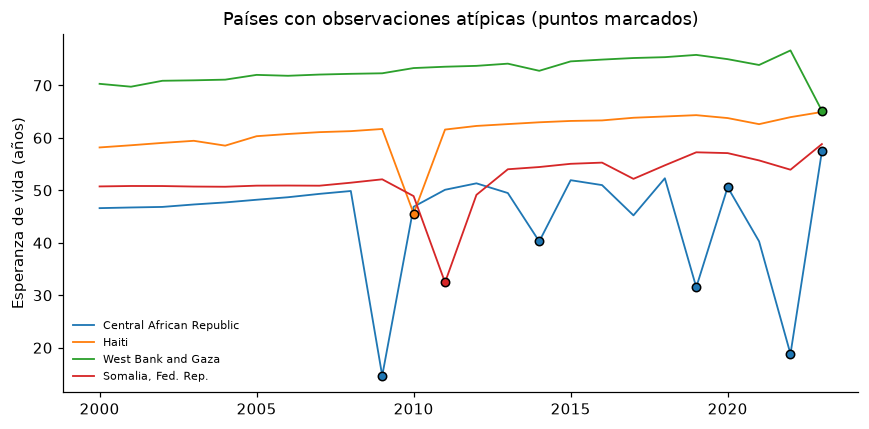

In [17]:
paises_atipicos = atipicos["nombre"].unique()
fig, ax = plt.subplots(figsize=(8, 4))
for nombre in paises_atipicos:
    g = panel[panel["nombre"] == nombre]
    linea, = ax.plot(g["anio"], g["esp_vida"], lw=1.2, label=nombre)
    marca = g[g["esp_vida_atipica"]]
    ax.scatter(marca["anio"], marca["esp_vida"], color=linea.get_color(), zorder=3, s=30, edgecolor="black")
ax.set_ylabel("Esperanza de vida (años)")
ax.set_title("Países con observaciones atípicas (puntos marcados)")
ax.legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

**¿Errores o hechos reales?** Los datos por sí solos no lo dicen. Varios casos coinciden con eventos conocidos: el terremoto de Haití (2010), la hambruna en Somalia (2011) o la guerra en Gaza (2023); y la fuente construye sus estimaciones incluyendo la mortalidad de las crisis. En cambio, las caídas aisladas de la República Centroafricana (por ejemplo, 14.7 años en 2009 entre valores cercanos a 50) **no se explican con lo que descargamos**; habría que consultar la documentación de la ONU.

Observa también un límite de la regla: en la República Centroafricana marca incluso valores normales (2020, 2023) porque sus años vecinos son erráticos. La regla es un **primer filtro para investigar**, no un veredicto.

Decisión, siguiendo la presentación (*investígalos antes de eliminarlos*): **se conservan los valores originales, se marcan** con `esp_vida_atipica` y, más adelante, se comprueba si las conclusiones cambian al excluirlos (**análisis de sensibilidad**). Eliminarlos en silencio sería tomar una decisión analítica sin documentarla.

Creamos ahora las variables derivadas (se registran como *Derivada* en el diccionario) y validamos la tabla con `assert`: si algo falla, el código se detiene.

In [18]:
panel["ln_pib_pc"] = np.log(panel["pib_pc"])
panel["pob_millones"] = panel["pob"] / 1e6

# ---- Validaciones ----
assert not panel["iso3"].isin(paises.loc[paises["es_agregado"] == 1, "iso3"]).any(), "Hay agregados en la tabla de países"
assert not panel.duplicated(["iso3", "anio"]).any(), "Hay filas país-año duplicadas"
assert panel["iso3"].str.len().eq(3).all()
assert panel["anio"].between(ANIO_INICIO, ANIO_FIN).all()
assert panel["esp_vida"].dropna().between(0, 100).all(), "Esperanza de vida físicamente imposible"
assert (panel["pib_pc"].dropna() > 0).all() and (panel["pob"].dropna() > 0).all()
assert panel["gasto_salud"].dropna().between(0, 40).all(), "Gasto en salud fuera de rango"
assert not panel["region"].str.endswith(" ").any(), "Quedan espacios sobrantes en las regiones"
print("Todas las validaciones pasaron.")
print("Tabla de análisis:", panel.shape)

Todas las validaciones pasaron.
Tabla de análisis: (5208, 12)


## 8. Agregación espacial: de países a regiones

Para la pregunta sobre regiones agregamos los países. Dos decisiones que se documentan:

- **Ponderación:** la esperanza de vida regional se calcula **ponderando por población**; la media simple trata igual a un país pequeño que a uno enorme.
- **Regla de calidad:** solo entran países con dato de esperanza de vida y de población en ese año.

Recuerda: la agregación es **irreversible**, por eso conservamos la tabla país-año.

In [19]:
def agregar_region(grupo):
    g = grupo.dropna(subset=["esp_vida", "pob"])
    return pd.Series({
        "n_paises": len(g),
        "pob_total_millones": g["pob"].sum() / 1e6,
        "esp_vida_simple": g["esp_vida"].mean(),
        "esp_vida_ponderada": np.average(g["esp_vida"], weights=g["pob"]),
    })

regiones = (panel.groupby(["region", "anio"])[["esp_vida", "pob"]]
                 .apply(agregar_region, include_groups=False)
                 .reset_index())
regiones["n_paises"] = regiones["n_paises"].astype(int)
regiones["diferencia_ponderada_menos_simple"] = regiones["esp_vida_ponderada"] - regiones["esp_vida_simple"]

regiones[regiones["anio"] == 2023].set_index("region")[
    ["n_paises", "pob_total_millones", "esp_vida_simple", "esp_vida_ponderada", "diferencia_ponderada_menos_simple"]
].sort_values("esp_vida_ponderada")

,n_paises,pob_total_millones,esp_vida_simple,esp_vida_ponderada,diferencia_ponderada_menos_simple
region,,,,,
África Subsahariana,48,1258.81,64.56,62.60,-1.95
"Oriente Medio, Norte de África, Afganistán y Pakistán",23,797.80,75.48,72.08,-3.39
Asia Meridional,6,1662.58,74.75,72.32,-2.43
América Latina y el Caribe,42,657.62,75.38,75.64,0.27
Asia Oriental y el Pacífico,37,2361.07,73.96,76.62,2.66
Europa y Asia Central,58,924.81,79.05,78.39,-0.66
América del Norte,3,376.87,80.77,78.73,-2.04


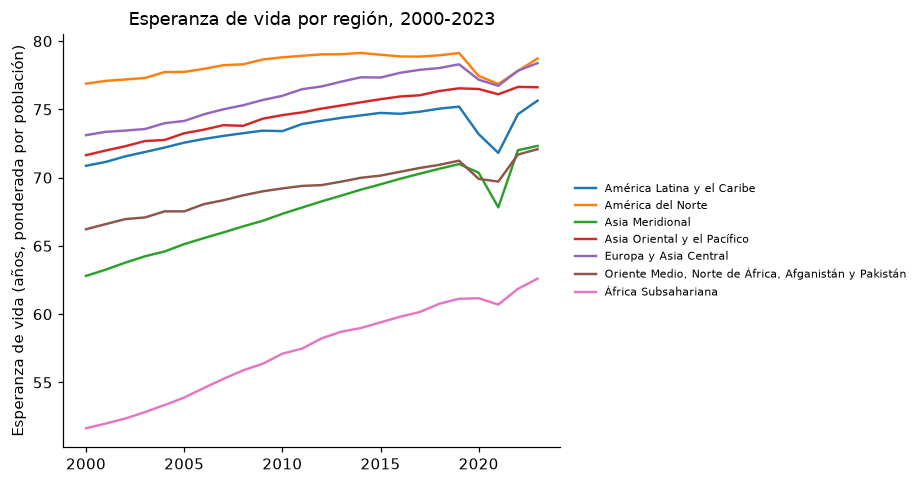

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for region, g in regiones.groupby("region"):
    ax.plot(g["anio"], g["esp_vida_ponderada"], lw=1.6, label=region)
ax.set_ylabel("Esperanza de vida (años, ponderada por población)")
ax.set_title("Esperanza de vida por región, 2000-2023")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.show()

### El nivel de agregación puede cambiar la conclusión

La pregunta específica 4 era: ¿cambia la relación entre ingreso y esperanza de vida al pasar de países a regiones? Comparamos la correlación calculada **entre países** con la calculada **entre regiones** (2022):

In [21]:
c22 = panel[(panel["anio"] == 2022)].dropna(subset=["esp_vida", "pib_pc", "pob"]).copy()

corr_paises = c22["ln_pib_pc"].corr(c22["esp_vida"])

def resumen_region(g):
    return pd.Series({
        "ln_pib_pc": np.log((g["pib_pc"] * g["pob"]).sum() / g["pob"].sum()),   # PIB per cápita regional ponderado
        "esp_vida": np.average(g["esp_vida"], weights=g["pob"]),
    })

por_region = c22.groupby("region")[["pib_pc", "pob", "esp_vida"]].apply(resumen_region, include_groups=False)
corr_regiones = por_region["ln_pib_pc"].corr(por_region["esp_vida"])

print(f"Correlación entre {len(c22)} países:   {corr_paises:.3f}")
print(f"Correlación entre {len(por_region)} regiones:  {corr_regiones:.3f}")

# Análisis de sensibilidad: ¿cambia la conclusión sin las observaciones atípicas?
sin_atipicos = c22[~c22["esp_vida_atipica"]]
print(f"\nSensibilidad: excluyendo {int(c22['esp_vida_atipica'].sum())} observación(es) atípica(s) en 2022 "
      f"-> correlación entre países: {sin_atipicos['ln_pib_pc'].corr(sin_atipicos['esp_vida']):.3f}")

Correlación entre 199 países:   0.809
Correlación entre 7 regiones:  0.883

Sensibilidad: excluyendo 1 observación(es) atípica(s) en 2022 -> correlación entre países: 0.847


**Sensibilidad.** Excluir una sola observación atípica (la de 2022 de la República Centroafricana) **cambia visiblemente** la correlación entre países. Una conclusión que depende de un único dato debe reportarse con esa advertencia: por eso conservamos el valor original, lo marcamos y mostramos ambos resultados.

La relación **se ve más fuerte al agregar**: al promediar, se cancela la variación entre países de una misma región. Esto no significa que la relación sea "más cierta" a nivel regional: significa que **la conclusión depende de la unidad de análisis**. Una afirmación sobre regiones no se puede trasladar a países individuales (*falacia ecológica*). Por eso la presentación insiste en elegir la granularidad que corresponde a la pregunta.

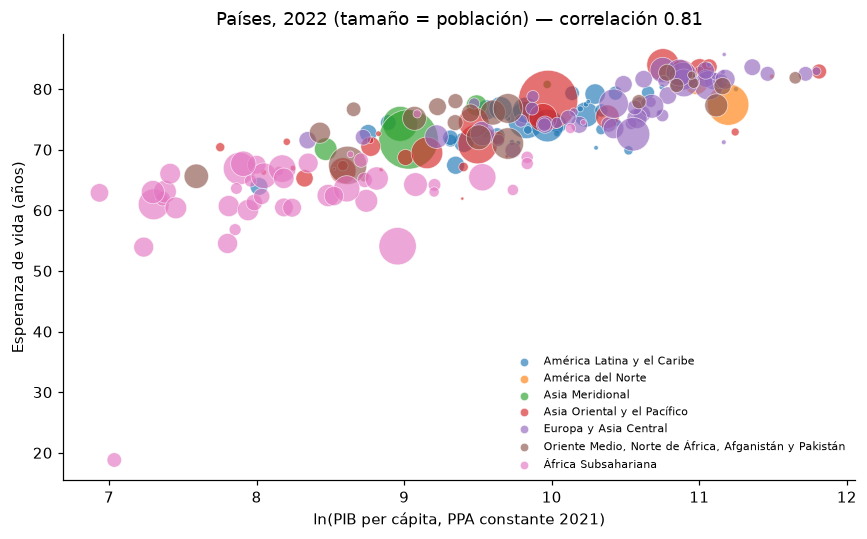

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
regiones_lista = sorted(c22["region"].unique())
colores = plt.cm.tab10(np.arange(len(regiones_lista)))
for color, region in zip(colores, regiones_lista):
    g = c22[c22["region"] == region]
    ax.scatter(g["ln_pib_pc"], g["esp_vida"], s=np.sqrt(g["pob"]) / 25, alpha=0.65, color=color, label=region, edgecolor="white", lw=0.5)
ax.set_xlabel("ln(PIB per cápita, PPA constante 2021)")
ax.set_ylabel("Esperanza de vida (años)")
ax.set_title(f"Países, 2022 (tamaño = población) — correlación {corr_paises:.2f}")
leyenda = ax.legend(fontsize=7, loc="lower right", frameon=False)
for marcador in leyenda.legend_handles:
    marcador.set_sizes([30])
plt.tight_layout()
plt.show()

> **Cuidado:** esto es una *asociación* observada en un año, no una explicación causal. El gráfico sirve para comprobar que la base permite abordar la pregunta; el análisis del proyecto requiere diseñar su método.

## 9. Entregables: diccionario, datasets, README y estructura de archivos

In [23]:
FUENTE = "Banco Mundial, World Development Indicators"

meta = {
    # variable: (tipo, unidad, descripcion, fuente, transformacion)
    "iso3": ("Texto", "código ISO 3166-1 alfa-3", "Identificador del país (llave primaria de `paises`)", FUENTE,
             "Sin cambios; se descartan observaciones sin iso3 (agregados)"),
    "nombre": ("Texto", "-", "Nombre del país (en inglés, como lo publica la fuente)", FUENTE, "Sin cambios"),
    "region": ("Categórica", "-", "Región según el Banco Mundial", FUENTE,
               "Espacios sobrantes eliminados; traducida al español"),
    "nivel_ingreso": ("Categórica", "-", "Nivel de ingreso según el Banco Mundial", FUENTE, "Traducida al español"),
    "anio": ("Entero", "año", "Año de la observación", FUENTE, "Sin cambios"),
    "esp_vida": ("Número", "años", "Esperanza de vida al nacer, total", FUENTE + " (ONU, World Population Prospects)",
                 "Sin cambios; sin imputación"),
    "pib_pc": ("Número", "dólares internacionales constantes de 2021 (PPA)", "PIB per cápita",
               FUENTE + " (Programa de Comparación Internacional)",
               "Sin cambios; NO imputado (faltan países completos); análisis de casos completos"),
    "pob": ("Número", "personas", "Población total", FUENTE + " (ONU, World Population Prospects)", "Sin cambios"),
    "gasto_salud": ("Número", "% del PIB", "Gasto corriente en salud", FUENTE + " (OMS, Global Health Expenditure Database)",
                    "Sin cambios; NO imputado"),
    "esp_vida_atipica": ("Sí/No", "-", "Esperanza de vida a más de 8 años de la mediana de los años vecinos (ventana de 5 años)", "Derivada",
                         "Regla de plausibilidad; el valor original se conserva"),
    "ln_pib_pc": ("Número", "log(dólares)", "Logaritmo natural del PIB per cápita", "Derivada", "log(pib_pc)"),
    "pob_millones": ("Número", "millones de personas", "Población en millones", "Derivada", "pob / 1,000,000"),
    # base regional
    "n_paises": ("Entero", "países", "Países con dato en la región y año", "Derivada", "Conteo tras la regla de calidad"),
    "pob_total_millones": ("Número", "millones de personas", "Población de los países con dato", "Derivada", "Suma de pob / 1,000,000"),
    "esp_vida_simple": ("Número", "años", "Media simple de la esperanza de vida de los países", "Derivada", "Agregación espacial (media simple)"),
    "esp_vida_ponderada": ("Número", "años", "Media de la esperanza de vida ponderada por población", "Derivada", "Agregación espacial (ponderada por pob)"),
    "diferencia_ponderada_menos_simple": ("Número", "años", "Diferencia entre la media ponderada y la simple", "Derivada", "Resta"),
}

def rango(serie):
    s = serie.dropna()
    if s.empty:
        return "sin datos"
    if pd.api.types.is_bool_dtype(serie):
        return "verdadero o falso"
    if pd.api.types.is_integer_dtype(serie):
        return f"{int(s.min())} a {int(s.max())}"
    if pd.api.types.is_numeric_dtype(serie):
        return f"{s.min():.2f} a {s.max():.2f}"
    return f"{s.nunique()} categorías distintas" if serie.dtype == object or str(serie.dtype) in ("str", "string") else f"{s.min()} a {s.max()}"

def armar_diccionario(base, archivo):
    filas = []
    for col in base.columns:
        tipo, unidad, desc, fuente, transf = meta[col]
        faltante = base[col].isna().mean()
        filas.append({
            "archivo": archivo, "variable": col, "tipo": tipo, "unidad": unidad,
            "valores_observados": rango(base[col]),
            "puede_estar_vacio": "Sí" if faltante > 0 else "No",
            "porcentaje_faltante": round(100 * faltante, 1),
            "descripcion": desc, "fuente": fuente, "transformacion_aplicada": transf,
        })
    return pd.DataFrame(filas)

columnas_panel = ["iso3", "nombre", "region", "nivel_ingreso", "anio", "esp_vida", "pib_pc", "pob", "gasto_salud", "esp_vida_atipica", "ln_pib_pc", "pob_millones"]
columnas_regiones = ["region", "anio", "n_paises", "pob_total_millones", "esp_vida_simple", "esp_vida_ponderada", "diferencia_ponderada_menos_simple"]
regiones_salida = regiones.drop(columns=[], errors="ignore")[["region", "anio"] + columnas_regiones[2:]]

diccionario = pd.concat([
    armar_diccionario(panel[columnas_panel], "panel_pais_anio.csv"),
    armar_diccionario(regiones_salida, "regiones_anio.csv"),
], ignore_index=True)
diccionario.head(6)

,archivo,variable,tipo,unidad,valores_observados,puede_estar_vacio,porcentaje_faltante,descripcion,fuente,transformacion_aplicada
0,panel_pais_anio.csv,iso3,Texto,código ISO 3166-1 alfa-3,217 categorías distintas,No,0.00,Identificador del país (llave primaria de `pai...,"Banco Mundial, World Development Indicators",Sin cambios; se descartan observaciones sin is...
1,panel_pais_anio.csv,nombre,Texto,-,217 categorías distintas,No,0.00,"Nombre del país (en inglés, como lo publica la...","Banco Mundial, World Development Indicators",Sin cambios
2,panel_pais_anio.csv,region,Categórica,-,7 categorías distintas,No,0.00,Región según el Banco Mundial,"Banco Mundial, World Development Indicators",Espacios sobrantes eliminados; traducida al es...
3,panel_pais_anio.csv,nivel_ingreso,Categórica,-,4 categorías distintas,No,0.00,Nivel de ingreso según el Banco Mundial,"Banco Mundial, World Development Indicators",Traducida al español
4,panel_pais_anio.csv,anio,Entero,año,2000 a 2023,No,0.00,Año de la observación,"Banco Mundial, World Development Indicators",Sin cambios
5,panel_pais_anio.csv,esp_vida,Número,años,14.66 a 86.37,No,0.00,"Esperanza de vida al nacer, total","Banco Mundial, World Development Indicators (O...",Sin cambios; sin imputación


In [24]:
panel[columnas_panel].to_csv(RAIZ / "datos/procesados/panel_pais_anio.csv", index=False)
regiones_salida.to_csv(RAIZ / "datos/procesados/regiones_anio.csv", index=False)
diccionario.to_csv(RAIZ / "datos/diccionario_datos.csv", index=False, encoding="utf-8")

esquema = '''Esquema de datos (SQLite: datos/procesados/wdi.sqlite)

paises(iso3 PK, nombre, region, nivel_ingreso, es_agregado)
indicadores(codigo PK, variable UNIQUE, nombre, organismo_fuente)
observaciones(iso3 FK -> paises, codigo FK -> indicadores, anio, valor)  PK = (iso3, codigo, anio)

Tabla de análisis: panel_pais_anio.csv (una fila por país-año), obtenida con una consulta SQL
que cruza países x años y une las observaciones (agregados excluidos).
'''
(RAIZ / "documentos/esquema_datos.txt").write_text(esquema, encoding="utf-8")
con.close()
print("Panel:", panel[columnas_panel].shape, "| Regiones:", regiones_salida.shape, "| Diccionario:", diccionario.shape)

Panel: (5208, 12) | Regiones: (168, 7) | Diccionario: (19, 10)


In [25]:
n_paises_sin_pib = int(sin_pib.sum())
readme = f'''# Indicadores del Banco Mundial: esperanza de vida, ingreso y gasto en salud (ejemplo)

Ejemplo didáctico de la Unidad 4 (Seminario de Proyecto I, MCDI). Integra varias fuentes en una base relacional y la convierte en una tabla de análisis.

## Pregunta de investigación
¿Cómo ha evolucionado la esperanza de vida en las regiones del mundo entre {ANIO_INICIO} y {ANIO_FIN}, y qué relación guarda con el nivel de ingreso y el gasto en salud de los países?

## Origen de los datos
- **Fuente:** Banco Mundial, *World Development Indicators* (WDI), mediante la API pública {API}.
- **Organismos originales:** ONU (World Population Prospects), Programa de Comparación Internacional, Organización Mundial de la Salud (Global Health Expenditure Database).
- **Fecha de descarga:** {FECHA_DESCARGA}. Las cifras se revisan periódicamente: una descarga posterior puede diferir.
- **Licencia:** CC BY 4.0 (hay que citar la fuente).
- **Cobertura:** {panel["iso3"].nunique()} países, {ANIO_INICIO}-{ANIO_FIN}, una fila por país-año.

## Estructura
```
datos/originales/       respuestas JSON de la API tal como se descargaron (no se modifican)
datos/procesados/       wdi.sqlite, panel_pais_anio.csv, regiones_anio.csv
datos/diccionario_datos.csv
documentos/esquema_datos.txt
README.md
```

## Transformaciones (el detalle está en el diccionario)
1. Se separaron los **agregados** (regiones, grupos de ingreso) de los países y se excluyeron del análisis.
2. Se eliminaron espacios sobrantes en las regiones y se tradujeron las categorías al español.
3. Se descartaron las observaciones sin código iso3 (agregados que no se pueden conectar).
4. Se cargó un modelo relacional (paises, indicadores, observaciones) con llaves primarias y foráneas, y se integró en una tabla ancha con SQL.
5. Se marcaron valores atípicos de esperanza de vida (`esp_vida_atipica`) sin eliminarlos; variables derivadas: `ln_pib_pc` y `pob_millones`.
6. **Sin imputación**: los faltantes son países completos ({n_paises_sin_pib} sin PIB per cápita); se trabaja con casos completos.
7. Agregación regional: media de la esperanza de vida ponderada por población.

## Limitaciones
- Son estimaciones de organismos internacionales; la comparabilidad entre países depende de cómo se estima cada cifra.
- Los países sin dato de PIB no son una muestra aleatoria; las conclusiones valen solo para los países con datos.
- La clasificación regional es una convención del Banco Mundial y puede cambiar.
- Una asociación entre ingreso y esperanza de vida no es una relación causal; la conclusión regional no se puede trasladar a países individuales.

## Referencias
World Bank. ({date.today().year}). *World Development Indicators* [Conjunto de datos]. https://datacatalog.worldbank.org/search/dataset/0037712/world-development-indicators
'''
(RAIZ / "README.md").write_text(readme, encoding="utf-8")
print(readme[:700], "...")

# Indicadores del Banco Mundial: esperanza de vida, ingreso y gasto en salud (ejemplo)

Ejemplo didáctico de la Unidad 4 (Seminario de Proyecto I, MCDI). Integra varias fuentes en una base relacional y la convierte en una tabla de análisis.

## Pregunta de investigación
¿Cómo ha evolucionado la esperanza de vida en las regiones del mundo entre 2000 y 2023, y qué relación guarda con el nivel de ingreso y el gasto en salud de los países?

## Origen de los datos
- **Fuente:** Banco Mundial, *World Development Indicators* (WDI), mediante la API pública https://api.worldbank.org/v2.
- **Organismos originales:** ONU (World Population Prospects), Programa de Comparación Internacional, Organización  ...


### Lista de buenas prácticas (cómo la cumple este ejemplo)

| Requisito | Dónde se cumple en este ejemplo |
|---|---|
| Archivo de base de datos creado | `datos/procesados/wdi.sqlite` (relacional) y `panel_pais_anio.csv` (tabla de análisis) |
| Herramienta utilizada | Python (pandas) y SQLite |
| Alineación metodológica explícita | Sección 1: pregunta → variable/métrica |
| Evaluación del origen de datos | Sección 2 y hallazgos de integridad de la sección 3 |
| Variables incluidas listadas | `diccionario_datos.csv` (tipo, unidad, rango y % faltante por variable) |
| Transformaciones documentadas | Columna `transformacion_aplicada` y README |
| Diccionario de datos completo | `datos/diccionario_datos.csv` |
| Video corto y PDF (Evidencia 4A) | **Los produces tú** con tu propia base |

## Referencias

World Bank. (2026). *World Development Indicators* [Conjunto de datos]. https://datacatalog.worldbank.org/search/dataset/0037712/world-development-indicators